In [77]:
import numpy as np
from sklearn.datasets import make_blobs

num_centroides = np.random.randint(1, 21)

print("Numero de Centroides Generados Aleatoriamente:")
print(num_centroides)

Numero de Centroides Generados Aleatoriamente:
10


In [78]:
def generar_centroides_distanciados(k, min_dist=2.5, rango_min=-15, rango_max=15):

    centroides = []
    intentos = 0
    max_intentos = 2000

    while len(centroides) < k and intentos < max_intentos:
        nuevo_centro = np.random.uniform(rango_min, rango_max, size=2)

        if len(centroides) == 0:
            centroides.append(nuevo_centro)
        else:
            distancias = np.linalg.norm(np.array(centroides) - nuevo_centro, axis=1)
            if np.all(distancias >= min_dist):
                centroides.append(nuevo_centro)

        intentos += 1

    return np.array(centroides)

blob_centers = generar_centroides_distanciados(k=num_centroides, min_dist=2.5, rango_min=-15, rango_max=15)
print(blob_centers)

[[-11.56614996 -12.10485563]
 [-13.86407539  10.10871595]
 [  0.68906424   0.84211643]
 [ -1.53459929 -13.86783627]
 [  5.28845882   7.80862184]
 [-10.27695157   4.28669746]
 [ -4.36111662 -12.01701701]
 [  6.5807279    1.35048497]
 [ -4.35618487  13.45506272]
 [ -4.0680709    0.47585863]]


In [79]:
k_real = len(blob_centers)
blob_std = np.full(num_centroides, 3.0)
print(blob_std)

[3. 3. 3. 3. 3. 3. 3. 3. 3. 3.]


In [80]:
n_puntos = 2000

X, y = make_blobs(n_samples=n_puntos, centers=blob_centers, cluster_std=blob_std, random_state=42)

print(f"Número de clusters generados: {k_real}")
print(f"Total de puntos generados en X: {X.shape[0]}")
print(f"Puntos por cluster: {n_puntos}")
print(f"Dispersión/Desviación estándar (std) por cluster: {np.round(blob_std, 2)}")

Número de clusters generados: 10
Total de puntos generados en X: 2000
Puntos por cluster: 2000
Dispersión/Desviación estándar (std) por cluster: [3. 3. 3. 3. 3. 3. 3. 3. 3. 3.]


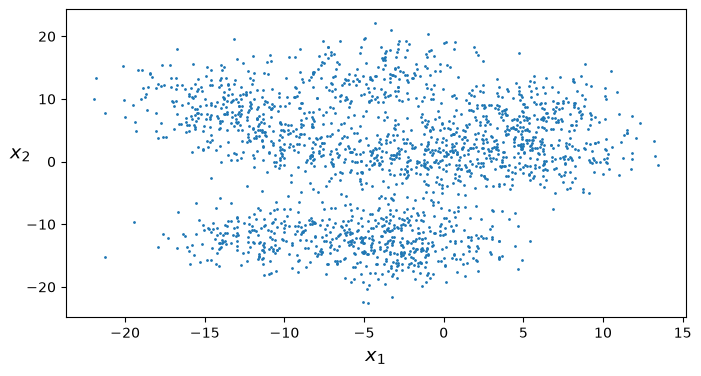

In [81]:
import matplotlib.pyplot as plt

def plot_clusters(X, y=None):
    plt.scatter(X[:, 0], X[:, 1], c=y, s=1)
    plt.xlabel("$x_1$", fontsize=14)
    plt.ylabel("$x_2$", fontsize=14, rotation=0)

plt.figure(figsize=(8, 4))
plot_clusters(X)
plt.show()

In [82]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=k_real, random_state=42, n_init=10)
y_pred = kmeans.fit_predict(X)

centroides_finales = kmeans.cluster_centers_

distancias = kmeans.transform(X)

print(y_pred)
print("\nMostrar Cordenadas\n")
print(centroides_finales)
print("\nDistancias de cada punto a cada centroide\n")
print(distancias)

[7 3 4 ... 0 1 7]

Mostrar Cordenadas

[[-12.08698322   6.00077122]
 [ -0.33418505   1.76510398]
 [-11.35992674 -12.05897263]
 [ -4.21181596  13.82108121]
 [ -2.30596571 -14.84040964]
 [  6.61005922   0.421397  ]
 [ -2.46264074  -8.6587836 ]
 [  5.42023018   8.35323494]
 [ -7.34338226   0.74689473]
 [-15.06950412  11.75160825]]

Distancias de cada punto a cada centroide

[[19.52267869 10.70007754 28.34992178 ...  2.02224624 16.87994429
  22.32283247]
 [ 9.01648986 14.67705016 26.39163921 ... 14.81707257 13.42659836
   7.25749904]
 [25.92740496 21.61516062  9.01741981 ... 29.70024982 19.95772567
  32.26515858]
 ...
 [ 0.88751803 12.09011368 17.19319872 ... 17.66614627  6.35339776
   7.32564359]
 [14.89840805  3.52757444 21.05634279 ...  5.44441147 10.39469792
  19.45309159]
 [17.3162433   7.73759613 25.38034203 ...  1.19165868 14.08881216
  20.76675686]]


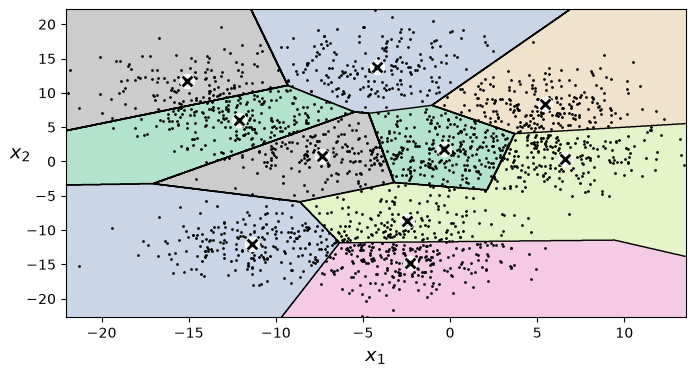

In [83]:
def plot_data(X):
    plt.plot(X[:, 0], X[:, 1], 'k.', markersize=2)

def plot_centroids(centroids, weights=None, circle_color='w', cross_color='k'):
    if weights is not None:
        centroids = centroids[weights > weights.max() / 10]
    plt.scatter(centroids[:, 0], centroids[:, 1],
                marker='o', s=10, linewidths=8,
                color=circle_color, zorder=10, alpha=0.9)
    plt.scatter(centroids[:, 0], centroids[:, 1],
                marker='x', s=2, linewidths=10,
                color=cross_color, zorder=11, alpha=1)

def plot_decision_boundaries(clusterer, X, resolution=1000, show_centroids=True,
                             show_xlabels=True, show_ylabels=True):
    mins = X.min(axis=0) - 0.1
    maxs = X.max(axis=0) + 0.1
    xx, yy = np.meshgrid(np.linspace(mins[0], maxs[0], resolution),
                         np.linspace(mins[1], maxs[1], resolution))
    Z = clusterer.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    plt.contourf(Z, extent=(mins[0], maxs[0], mins[1], maxs[1]),
                cmap="Pastel2")
    plt.contour(Z, extent=(mins[0], maxs[0], mins[1], maxs[1]),
                linewidths=1, colors='k')
    plot_data(X)
    if show_centroids:
        plot_centroids(clusterer.cluster_centers_)

    if show_xlabels:
        plt.xlabel("$x_1$", fontsize=14)
    else:
        plt.tick_params(labelbottom=False)
    if show_ylabels:
        plt.ylabel("$x_2$", fontsize=14, rotation=0)
    else:
        plt.tick_params(labelleft=False)

plt.figure(figsize=(8, 4))
plot_decision_boundaries(kmeans, X)
plt.show()

In [96]:
X_new = np.array([[-5, 10], [5, 10], [8, 1], [-10, 1.5]])
kmeans.predict(X_new)

array([3, 7, 5, 8], dtype=int32)

In [97]:
kmeans.transform(X_new)

array([[ 8.13751572,  9.46484768, 22.95750295,  3.90152479, 24.98607155,
        15.05134912, 18.83051772, 10.54955128,  9.54522904, 10.22071644],
       [17.5487557 ,  9.81157697, 27.46352994,  9.97287396, 25.89252954,
         9.7129772 , 20.09580087,  1.69953775, 15.42656938, 20.14579676],
       [20.7001113 ,  8.36923082, 23.3525915 , 17.70617329, 18.89792335,
         1.50556196, 14.23934521,  7.79264246, 15.34546974, 25.45189777],
       [ 4.96109268,  9.66944977, 13.62700039, 13.61293931, 18.06120568,
        16.64504285, 12.64961141, 16.87454675,  2.76130138, 11.4365792 ]])

In [98]:
kmeans_iter1 = KMeans(n_clusters=k_real, init="k-means++", n_init=1, algorithm="lloyd", max_iter=1, random_state=1)
kmeans_iter2 = KMeans(n_clusters=k_real, init="k-means++", n_init=1, algorithm="lloyd", max_iter=20, random_state=1)
kmeans_iter3 = KMeans(n_clusters=k_real, init="k-means++", n_init=1, algorithm="lloyd", max_iter=40, random_state=1)

kmeans_iter1.fit(X)
kmeans_iter2.fit(X)
kmeans_iter3.fit(X)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",10
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",1
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",40
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",1
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](10, 2)","[[ -6.

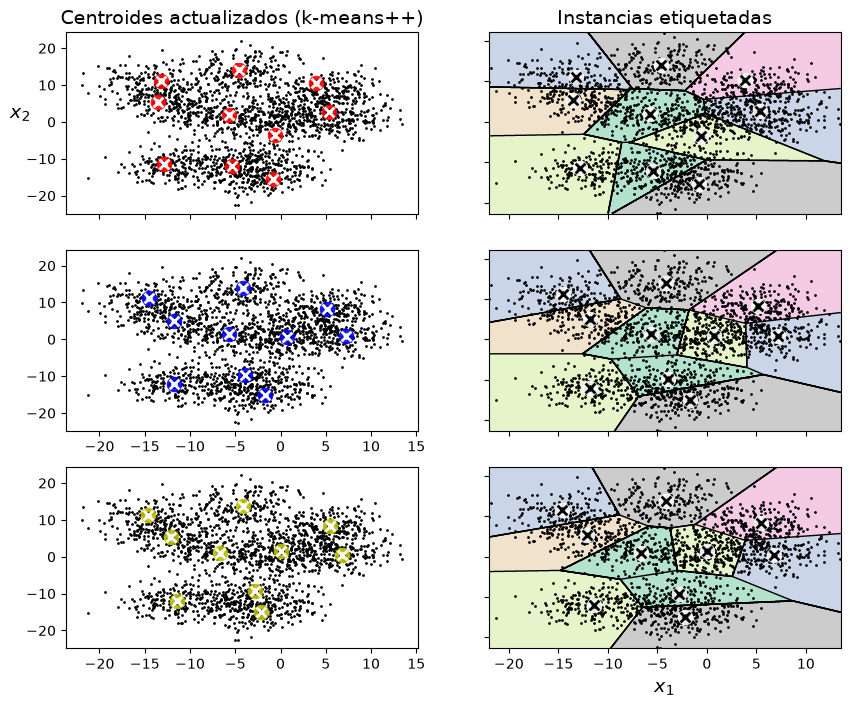

In [99]:
plt.figure(figsize=(10, 8))

plt.subplot(321)
plot_data(X)
plot_centroids(kmeans_iter1.cluster_centers_, circle_color='r', cross_color='w')
plt.ylabel("$x_2$", fontsize=14, rotation=0)
plt.tick_params(labelbottom=False)
plt.title("Centroides actualizados (k-means++)", fontsize=14)

plt.subplot(322)
plot_decision_boundaries(kmeans_iter1, X, show_xlabels=False, show_ylabels=False)
plt.title("Instancias etiquetadas", fontsize=14)

plt.subplot(323)
# plot_decision_boundaries(kmeans_iter2, X, show_centroids=False, show_xlabels=False)
plot_data(X)
plot_centroids(kmeans_iter2.cluster_centers_, circle_color='b', cross_color='w')

plt.subplot(324)
plot_decision_boundaries(kmeans_iter2, X, show_xlabels=False, show_ylabels=False)

plt.subplot(325)
# plot_decision_boundaries(kmeans_iter2, X, show_centroids=False)
plot_data(X)
plot_centroids(kmeans_iter3.cluster_centers_, circle_color='y', cross_color='w')

plt.subplot(326)
plot_decision_boundaries(kmeans_iter3, X, show_ylabels=False)

plt.show()

In [100]:
kmeans_iter1_lkn = KMeans(n_clusters=k_real, init="k-means++", n_init=1, algorithm="elkan", max_iter=1, random_state=1)
kmeans_iter2_lkn = KMeans(n_clusters=k_real, init="k-means++", n_init=1, algorithm="elkan", max_iter=20, random_state=1)
kmeans_iter3_lkn = KMeans(n_clusters=k_real, init="k-means++", n_init=1, algorithm="elkan", max_iter=40, random_state=1)

kmeans_iter1_lkn.fit(X)
kmeans_iter2_lkn.fit(X)
kmeans_iter3_lkn.fit(X)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",10
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",1
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",40
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",1
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'elkan'
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](10, 2)","[[ -6.

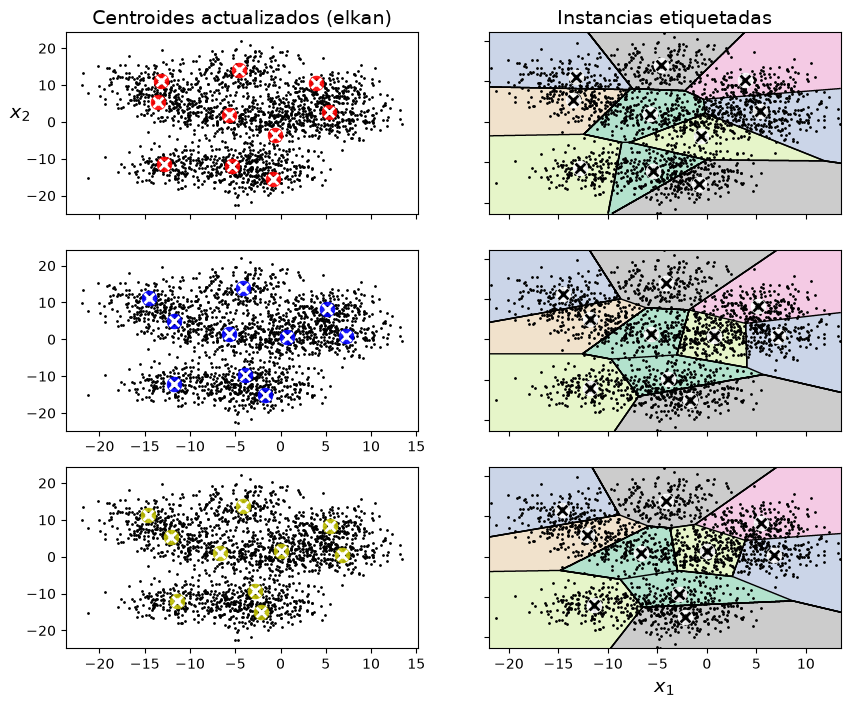

In [101]:
plt.figure(figsize=(10, 8))

plt.subplot(321)
plot_data(X)
plot_centroids(kmeans_iter1_lkn.cluster_centers_, circle_color='r', cross_color='w')
plt.ylabel("$x_2$", fontsize=14, rotation=0)
plt.tick_params(labelbottom=False)
plt.title("Centroides actualizados (elkan)", fontsize=14)

plt.subplot(322)
plot_decision_boundaries(kmeans_iter1_lkn, X, show_xlabels=False, show_ylabels=False)
plt.title("Instancias etiquetadas", fontsize=14)

plt.subplot(323)
# plot_decision_boundaries(kmeans_iter2, X, show_centroids=False, show_xlabels=False)
plot_data(X)
plot_centroids(kmeans_iter2_lkn.cluster_centers_, circle_color='b', cross_color='w')

plt.subplot(324)
plot_decision_boundaries(kmeans_iter2_lkn, X, show_xlabels=False, show_ylabels=False)

plt.subplot(325)
# plot_decision_boundaries(kmeans_iter2, X, show_centroids=False)
plot_data(X)
plot_centroids(kmeans_iter3_lkn.cluster_centers_, circle_color='y', cross_color='w')

plt.subplot(326)
plot_decision_boundaries(kmeans_iter3_lkn, X, show_ylabels=False)

plt.show()

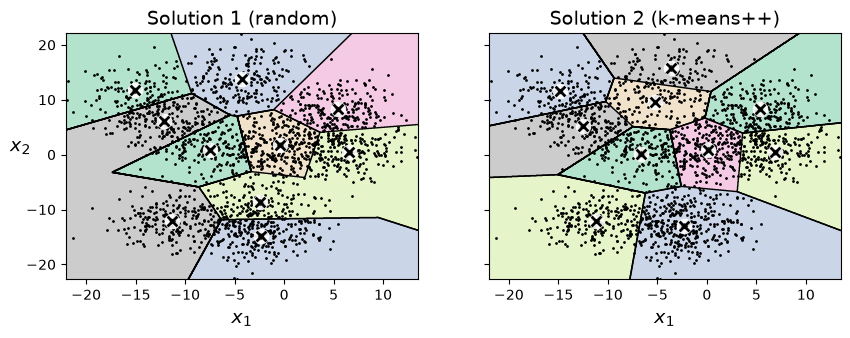

In [103]:
def plot_clusterer_comparison(clusterer1, clusterer2, X, title1=None, title2=None):
    clusterer1.fit(X)
    clusterer2.fit(X)

    plt.figure(figsize=(10, 3.2))

    plt.subplot(121)
    plot_decision_boundaries(clusterer1, X)
    if title1:
        plt.title(title1, fontsize=14)

    plt.subplot(122)
    plot_decision_boundaries(clusterer2, X, show_ylabels=False)
    if title2:
        plt.title(title2, fontsize=14)

kmeans_rnd_init1 = KMeans(n_clusters=k_real, init="random", n_init=1, algorithm="elkan", random_state=19)
kmeans_rnd_init2 = KMeans(n_clusters=k_real, init="k-means++", n_init=1, algorithm="lloyd", random_state=19)

plot_clusterer_comparison(kmeans_rnd_init1, kmeans_rnd_init2, X,"Solution 1 (random)", "Solution 2 (k-means++)")

plt.show()

In [106]:
kmeans_rnd_1_inits = KMeans(n_clusters=k_real, init="random", n_init=1, algorithm="elkan", random_state=11)
kmeans_rnd_1_inits.fit(X)

kmeans_rnd_10_inits = KMeans(n_clusters=k_real, init="random", n_init=5, algorithm="elkan", random_state=11)
kmeans_rnd_10_inits.fit(X)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",10
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'random'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",5
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",11
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'elkan'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](10, 2)","[[ -4.2

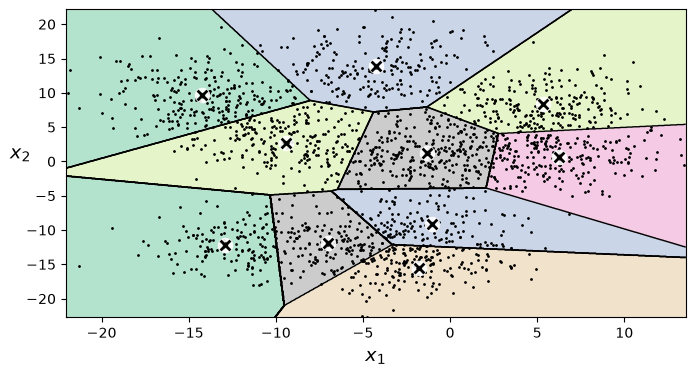

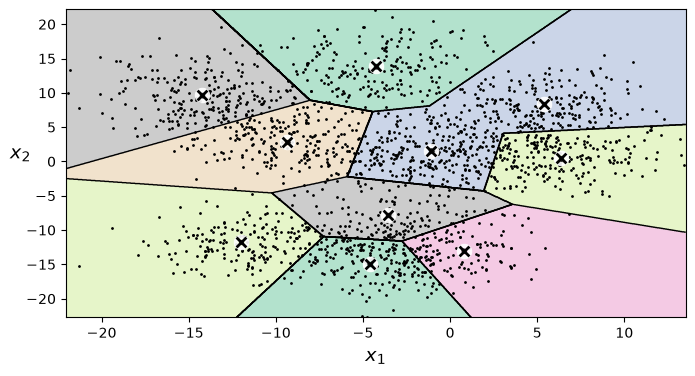

In [107]:
plt.figure(figsize=(8, 4))
plot_decision_boundaries(kmeans_rnd_1_inits, X)
plt.show()

plt.figure(figsize=(8, 4))
plot_decision_boundaries(kmeans_rnd_10_inits, X)
plt.show()

In [108]:
from sklearn.metrics import silhouette_score
silhouette_score(X, kmeans.labels_)

0.3721603228263404

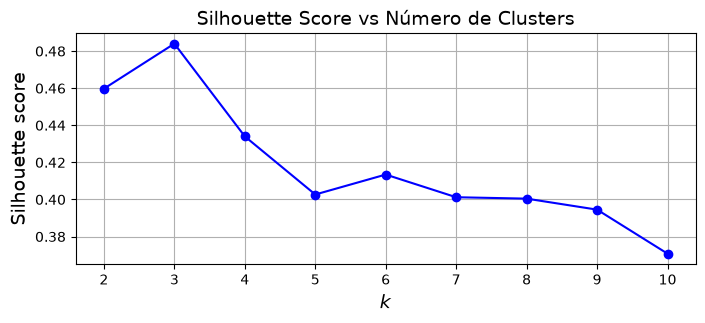

In [109]:
kmeans_per_k = [KMeans(n_clusters=k_real, random_state=42).fit(X) for k_real in range(1, 10)]
silhouette_scores = [silhouette_score(X, model.labels_) for model in kmeans_per_k[1:]]

max_k = min(20, len(blob_centers))  # no más de los centros generados
kmeans_per_k = [KMeans(n_clusters=k_real, random_state=42).fit(X) for k_real in range(1, max_k + 1)]
silhouette_scores = [silhouette_score(X, model.labels_) for model in kmeans_per_k[1:]]

ks = list(range(2, max_k + 1))

plt.figure(figsize=(8, 3))
plt.plot(ks, silhouette_scores, "bo-")
plt.xlabel("$k$", fontsize=14)
plt.ylabel("Silhouette score", fontsize=14)
plt.title("Silhouette Score vs Número de Clusters", fontsize=14)
plt.grid(True)
plt.show()

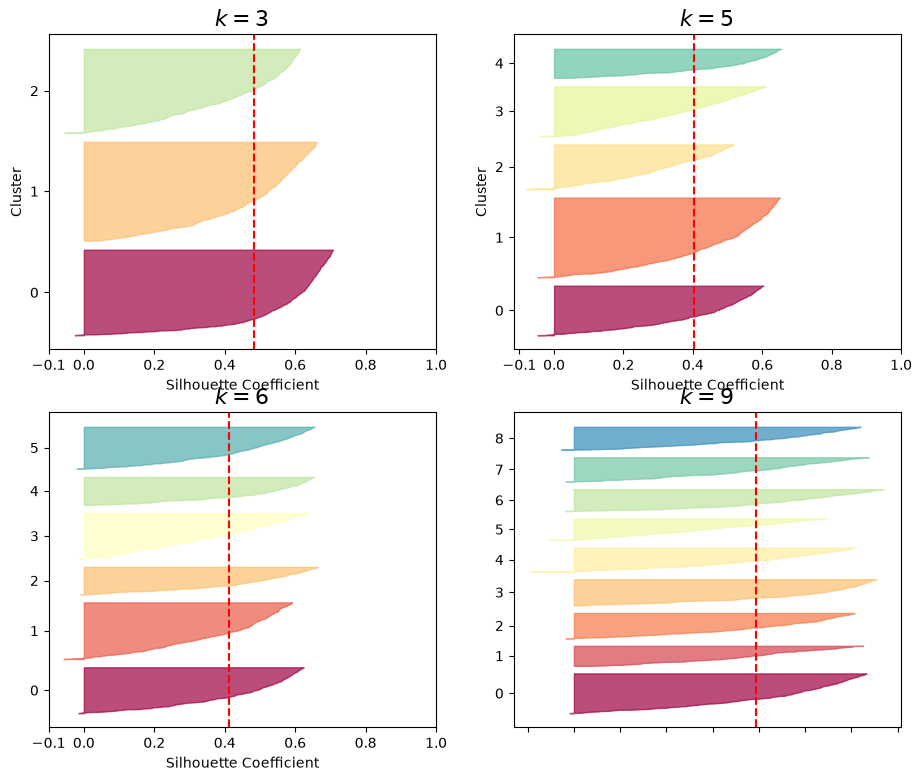

In [110]:
from sklearn.metrics import silhouette_samples
from matplotlib.ticker import FixedLocator, FixedFormatter
import matplotlib as mpl

plt.figure(figsize=(11, 9))

valid_ks = [k for k in (3, 5, 6, 9) if k <= len(kmeans_per_k)]  # Filtrar solo los ks válidos


for plot_idx, k in enumerate(valid_ks):
    plt.subplot(2, 2, plot_idx + 1)  # enumerar para evitar errores


    y_pred = kmeans_per_k[k - 1].labels_
    silhouette_coefficients = silhouette_samples(X, y_pred)

    padding = len(X) // 30
    pos = padding
    ticks = []
    for i in range(k):
        coeffs = silhouette_coefficients[y_pred == i]
        coeffs.sort()

        color = mpl.cm.Spectral(i / k)
        plt.fill_betweenx(np.arange(pos, pos + len(coeffs)), 0, coeffs,
                          facecolor=color, edgecolor=color, alpha=0.7)
        ticks.append(pos + len(coeffs) // 2)
        pos += len(coeffs) + padding

    plt.gca().yaxis.set_major_locator(FixedLocator(ticks))
    plt.gca().yaxis.set_major_formatter(FixedFormatter(range(k)))
    if k in (3, 5):
        plt.ylabel("Cluster")

    if k in (3, 4, 5, 6):
        plt.gca().set_xticks([-0.1, 0, 0.2, 0.4, 0.6, 0.8, 1])
        plt.xlabel("Silhouette Coefficient")
    else:
        plt.tick_params(labelbottom=False)

    plt.axvline(x=silhouette_scores[k - 2], color="red", linestyle="--")
    plt.title("$k={}$".format(k), fontsize=16)

plt.show()